<a href="https://colab.research.google.com/github/anandhakannanww-alt-coder/walmart-sales-forecasting/blob/main/Capstone_Walmart_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor

try:
    from IPython.display import display
except ImportError:
    display = print

In [34]:
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 200)

DATA_PATH = "/content/Walmart DataSet.csv"

In [35]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
display(df.head())
df.info()

# Date is dd-mm-yyyy text -> convert to real datetime
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

num_cols = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]

#  Missing values
print("\nMissing values per column:\n", df.isnull().sum())
if df[num_cols].isnull().any().any():
    # fill within each store using time-based interpolation
    df = df.sort_values(["Store", "Date"])
    df[num_cols] = df.groupby("Store")[num_cols].transform(
        lambda s: s.interpolate().ffill().bfill())
    print("Missing values were filled store-wise (interpolation).")
else:
    print("-> No missing values found. Nothing to impute.")


Shape: (6435, 8)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,"1,643,690.900",0,42.310,2.572,211.096,8.106
1,1,12-02-2010,"1,641,957.440",1,38.510,2.548,211.242,8.106
2,1,19-02-2010,"1,611,968.170",0,39.930,2.514,211.289,8.106
3,1,26-02-2010,"1,409,727.590",0,46.630,2.561,211.320,8.106
4,1,05-03-2010,"1,554,806.680",0,46.500,2.625,211.350,8.106


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB

Missing values per column:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
-> No missing values found. Nothing to impute.


In [36]:
# Duplicates
dups = df.duplicated().sum()
df = df.drop_duplicates().sort_values(["Store", "Date"]).reset_index(drop=True)
print("Duplicate rows removed:", dups)

Duplicate rows removed: 0


In [37]:

#  Sanity checks
print("Stores:", df["Store"].nunique(), "| Weeks per store:", df.groupby("Store").size().unique())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Holiday weeks (dates):", sorted(df.loc[df.Holiday_Flag == 1, "Date"].dt.strftime("%Y-%m-%d").unique()))

Stores: 45 | Weeks per store: [143]
Date range: 2010-02-05 to 2012-10-26
Holiday weeks (dates): ['2010-02-12', '2010-09-10', '2010-11-26', '2010-12-31', '2011-02-11', '2011-09-09', '2011-11-25', '2011-12-30', '2012-02-10', '2012-09-07']


In [38]:

# Helper columns
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

In [53]:

# Stores differ hugely in size, so we also use a size-free index (1.0 = that store's own average)

df["Sales_Index"] = df["Weekly_Sales"] / df.groupby("Store")["Weekly_Sales"].transform("mean")

# Within-store centred versions of the drivers (removes store-to-store level differences)

for c in ["Temperature", "Fuel_Price", "CPI", "Unemployment"]:
    df[c + "_dm"] = df[c] - df.groupby("Store")[c].transform("mean")

sales_wide = df.pivot(index="Date", columns="Store", values="Weekly_Sales").sort_index()
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
Store,"6,435.000",23.000,1.000,12.000,23.000,34.000,45.000,12.988
Date,6435,2011-06-17 00:00:00,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,"6,435.000","1,046,964.878","209,986.250","553,350.105","960,746.040","1,420,158.660","3,818,686.450","564,366.622"
Holiday_Flag,"6,435.000",0.070,0.000,0.000,0.000,0.000,1.000,0.255
Temperature,"6,435.000",60.664,-2.060,47.460,62.670,74.940,100.140,18.445
Fuel_Price,"6,435.000",3.359,2.472,2.933,3.445,3.735,4.468,0.459
CPI,"6,435.000",171.578,126.064,131.735,182.617,212.743,227.233,39.357
Unemployment,"6,435.000",7.999,3.879,6.891,7.874,8.622,14.313,1.876
Year,"6,435.000","2,010.965","2,010.000","2,010.000","2,011.000","2,012.000","2,012.000",0.797
Month,"6,435.000",6.448,1.000,4.000,6.000,9.000,12.000,3.238


,Column,Outliers,Percent
0,Weekly_Sales,300,4.662
1,Temperature,0,0.000
2,Fuel_Price,0,0.000
3,CPI,0,0.000
4,Unemployment,32,0.497



Weekly_Sales outliers: 300 rows
  -> 85% fall in Nov/Dec, 28% are flagged holiday weeks
DECISION: outliers are genuine festive-season demand spikes (not data errors), so they are KEPT.


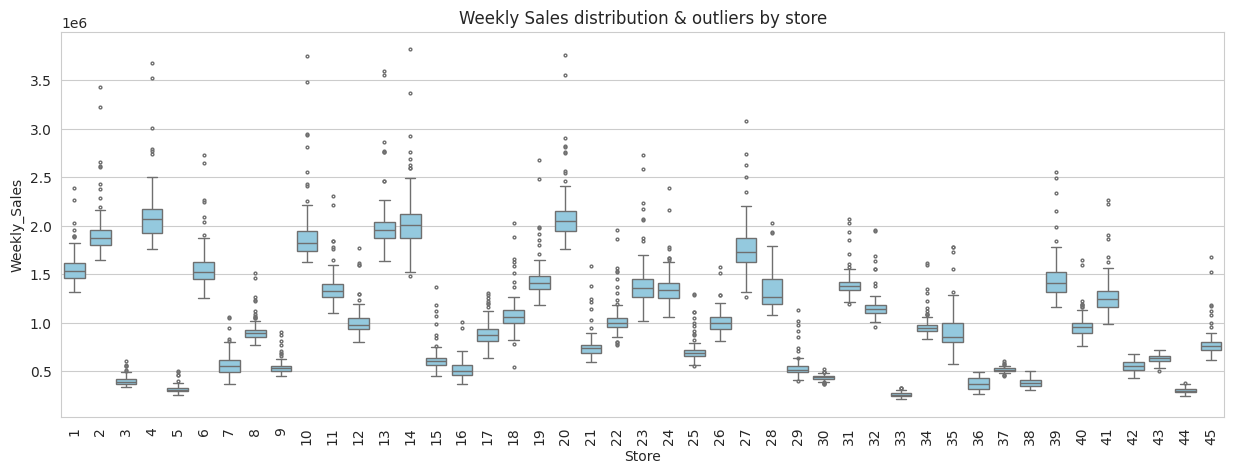

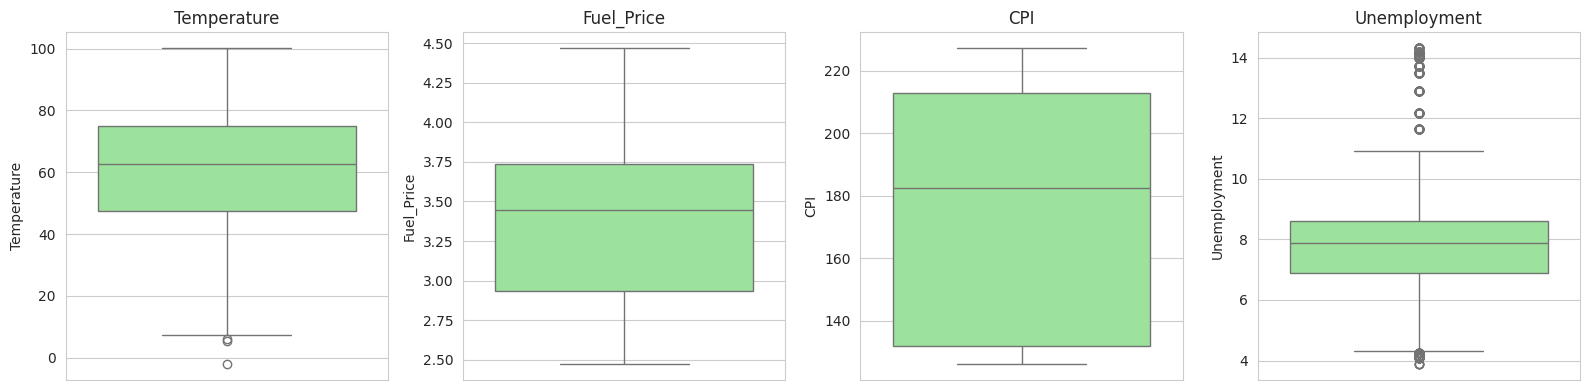

In [40]:
#OUTLIER ANALYSIS (IQR method, done per store because stores differ in size)
def iqr_mask(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out_rows = []
for c in num_cols:
    m = df.groupby("Store")[c].transform(iqr_mask).astype(bool)
    df[c + "_outlier"] = m
    out_rows.append({"Column": c, "Outliers": int(m.sum()), "Percent": m.mean() * 100})
display(pd.DataFrame(out_rows))

o = df[df["Weekly_Sales_outlier"]]
print(f"\nWeekly_Sales outliers: {len(o)} rows")
print(f"  -> {(o.Month.isin([11, 12])).mean() * 100:.0f}% fall in Nov/Dec, "
      f"{(o.Holiday_Flag == 1).mean() * 100:.0f}% are flagged holiday weeks")
print("DECISION: outliers are genuine festive-season demand spikes (not data errors), so they are KEPT.")

fig, ax = plt.subplots(figsize=(15, 5))
sns.boxplot(data=df, x="Store", y="Weekly_Sales", ax=ax, color="skyblue", fliersize=2)
ax.set_title("Weekly Sales distribution & outliers by store")
plt.xticks(rotation=90); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for a, c in zip(axes, ["Temperature", "Fuel_Price", "CPI", "Unemployment"]):
    sns.boxplot(y=df[c], ax=a, color="lightgreen"); a.set_title(c)
plt.tight_layout(); plt.show()


OVERALL (store-adjusted): Pearson r = -0.055 (p=0.0000) | Spearman rho = -0.132 (p=0.0000)
Stores with SIGNIFICANT NEGATIVE relation: 14 | significant POSITIVE: 5 | not significant: 26

Stores suffering MOST when unemployment rises (most negative, significant):


,Correlation,P_value,Pct_sales_change_per_1pt_unemp,Significant
Store,,,,
38,-0.785,0.000,-7.207,True
44,-0.780,0.000,-6.659,True
39,-0.385,0.000,-8.207,True
42,-0.356,0.000,-3.816,True
41,-0.351,0.000,-13.104,True
4,-0.337,0.000,-3.013,True
17,-0.264,0.001,-10.165,True
3,-0.230,0.006,-5.926,True
37,-0.221,0.008,-1.325,True


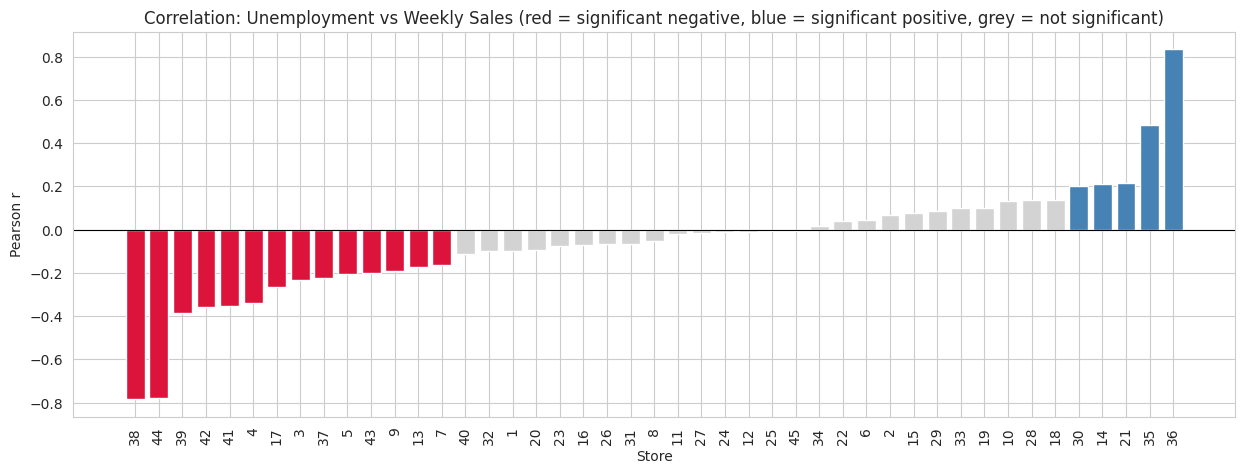

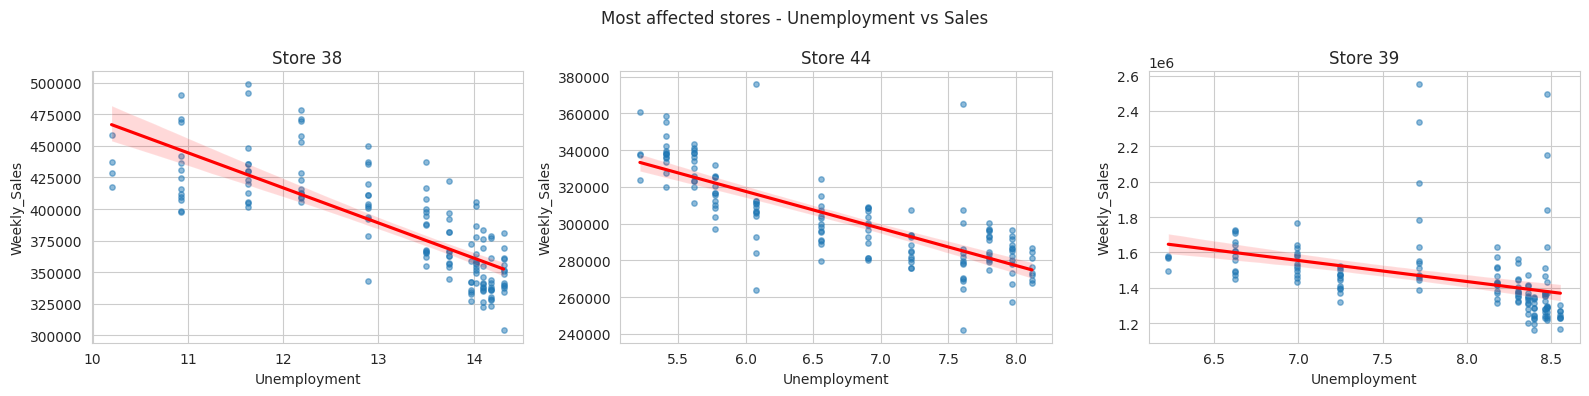

In [41]:
# Q1(a) UNEMPLOYMENT vs WEEKLY SALES
rows = []
for s, g in df.groupby("Store"):
    r, p = stats.pearsonr(g["Unemployment"], g["Weekly_Sales"])
    lr = stats.linregress(g["Unemployment"], g["Weekly_Sales"])
    rows.append({"Store": s, "Correlation": r, "P_value": p,
                 "Pct_sales_change_per_1pt_unemp": lr.slope / g["Weekly_Sales"].mean() * 100})
ue = pd.DataFrame(rows).set_index("Store")
ue["Significant"] = ue["P_value"] < 0.05

r_all, p_all = stats.pearsonr(df["Unemployment_dm"], df["Sales_Index"])
rho_all, prho_all = stats.spearmanr(df["Unemployment_dm"], df["Sales_Index"])
print(f"OVERALL (store-adjusted): Pearson r = {r_all:.3f} (p={p_all:.4f}) | Spearman rho = {rho_all:.3f} (p={prho_all:.4f})")

neg = ue[(ue.Significant) & (ue.Correlation < 0)].sort_values("Correlation")
pos = ue[(ue.Significant) & (ue.Correlation > 0)]
print(f"Stores with SIGNIFICANT NEGATIVE relation: {len(neg)} | significant POSITIVE: {len(pos)} | not significant: {(~ue.Significant).sum()}")
print("\nStores suffering MOST when unemployment rises (most negative, significant):")
display(neg.head(10))

plt.figure(figsize=(15, 5))
ue_sorted = ue.sort_values("Correlation")
colors = ["crimson" if (sig and c < 0) else "steelblue" if sig else "lightgrey"
          for sig, c in zip(ue_sorted.Significant, ue_sorted.Correlation)]
plt.bar(ue_sorted.index.astype(str), ue_sorted.Correlation, color=colors)
plt.axhline(0, color="black", lw=0.8)
plt.title("Correlation: Unemployment vs Weekly Sales (red = significant negative, blue = significant positive, grey = not significant)")
plt.xlabel("Store"); plt.ylabel("Pearson r"); plt.xticks(rotation=90); plt.show()

worst3 = neg.index[:3] if len(neg) >= 3 else ue.sort_values("Correlation").index[:3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for a, s in zip(axes, worst3):
    sns.regplot(data=df[df.Store == s], x="Unemployment", y="Weekly_Sales", ax=a,
                scatter_kws={"alpha": .5, "s": 15}, line_kws={"color": "red"})
    a.set_title(f"Store {s}")
plt.suptitle("Most affected stores - Unemployment vs Sales"); plt.tight_layout(); plt.show()

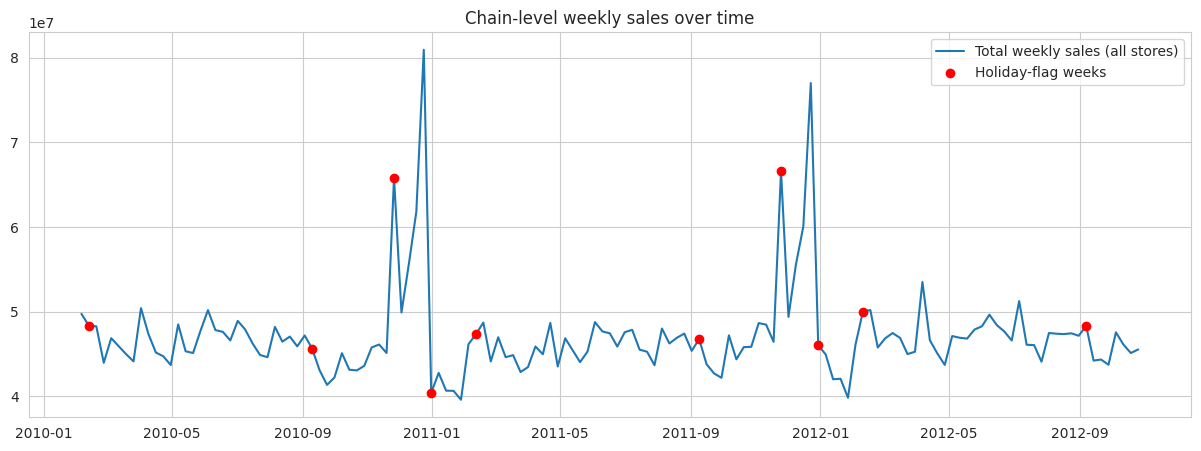

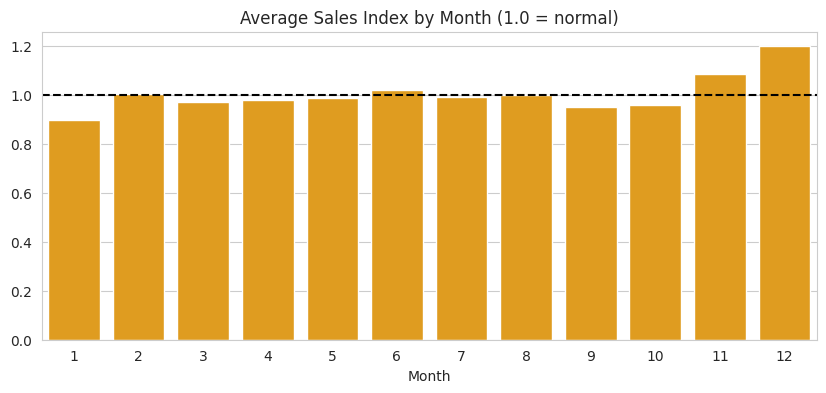

Peak months: {12: 1.198, 11: 1.086, 6: 1.018}
Lowest months: {1: 0.896, 9: 0.951, 10: 0.958}


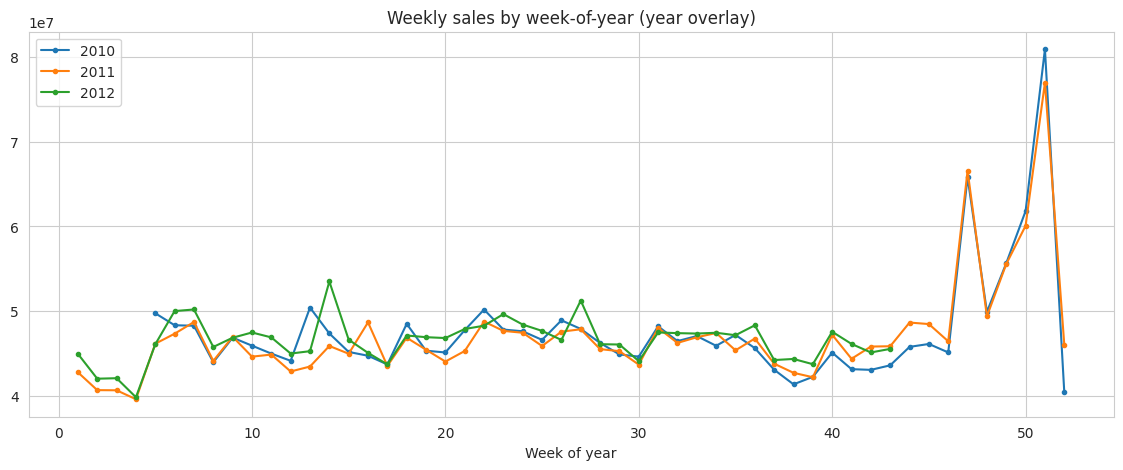

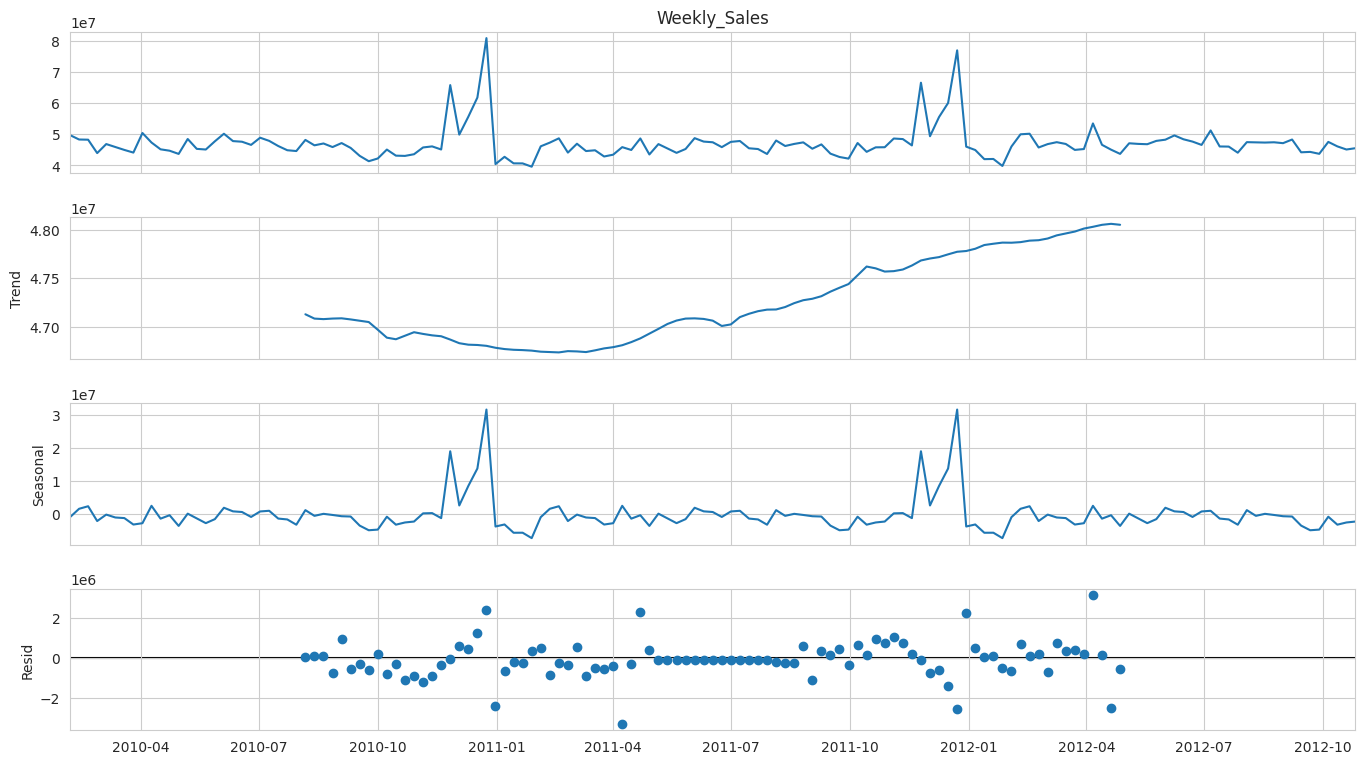


Top 10 weeks by total sales:


,Total_Sales,Holiday_Flag
Date,,
2010-12-24,"80,931,415.600",0
2011-12-23,"76,998,241.310",0
2011-11-25,"66,593,605.260",1
2010-11-26,"65,821,003.240",1
2010-12-17,"61,820,799.850",0
2011-12-16,"60,085,695.940",0
2010-12-10,"55,666,770.390",0
2011-12-09,"55,561,147.700",0
2012-04-06,"53,502,315.870",0



Holiday-week uplift vs normal weeks:


,Avg_Sales_Index,Uplift_vs_normal_%
Holiday_Name,,
Christmas/New Year,0.921,-7.410
Labor Day,1.000,0.563
Super Bowl,1.029,3.421
Thanksgiving,1.376,38.338


Pre-Christmas shopping weeks (Dec 15-25): uplift = 44.2%  (NOTE: dataset's 'Christmas' flag marks the week AFTER Christmas, the real peak is the week BEFORE)

Holiday vs non-holiday: Welch t=7.42, p=5.606e-13 | Mann-Whitney p=8.158e-12
Month effect (Kruskal-Wallis): H=1040.0, p=4.633e-216  -> SEASONALITY CONFIRMED


In [42]:
# Q1(b) SEASONAL TREND
weekly_total = df.groupby("Date")["Weekly_Sales"].sum()
hol_dates = df.loc[df.Holiday_Flag == 1, "Date"].unique()

plt.figure(figsize=(15, 5))
plt.plot(weekly_total.index, weekly_total.values, label="Total weekly sales (all stores)")
hw = weekly_total[weekly_total.index.isin(hol_dates)]
plt.scatter(hw.index, hw.values, color="red", zorder=5, label="Holiday-flag weeks")
plt.title("Chain-level weekly sales over time"); plt.legend(); plt.show()

# Month pattern (size-free index)
month_idx = df.groupby("Month")["Sales_Index"].mean()
plt.figure(figsize=(10, 4))
sns.barplot(x=month_idx.index, y=month_idx.values, color="orange")
plt.axhline(1, color="black", ls="--"); plt.title("Average Sales Index by Month (1.0 = normal)")
plt.show()
print("Peak months:", month_idx.sort_values(ascending=False).head(3).round(3).to_dict())
print("Lowest months:", month_idx.sort_values().head(3).round(3).to_dict())

# Year overlay by week number
tmp = weekly_total.to_frame("Sales")
tmp["Year"] = tmp.index.year; tmp["Week"] = tmp.index.isocalendar().week.astype(int).values
plt.figure(figsize=(14, 5))
for y, g in tmp.groupby("Year"):
    plt.plot(g["Week"], g["Sales"], marker="o", ms=3, label=str(y))
plt.title("Weekly sales by week-of-year (year overlay)"); plt.xlabel("Week of year"); plt.legend(); plt.show()

# Seasonal decomposition (52-week cycle)
dec = seasonal_decompose(weekly_total, model="additive", period=52)
dec.plot(); plt.gcf().set_size_inches(14, 8); plt.show()

# Top weeks
top_weeks = df.groupby("Date").agg(Total_Sales=("Weekly_Sales", "sum"), Holiday_Flag=("Holiday_Flag", "max"))
print("\nTop 10 weeks by total sales:")
display(top_weeks.sort_values("Total_Sales", ascending=False).head(10))

# Holiday analysis
hol = df[df.Holiday_Flag == 1].copy()
hol["Holiday_Name"] = hol["Month"].map({2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas/New Year"})
base = df.loc[df.Holiday_Flag == 0, "Sales_Index"].mean()
uplift = hol.groupby("Holiday_Name")["Sales_Index"].mean().to_frame("Avg_Sales_Index")
uplift["Uplift_vs_normal_%"] = (uplift["Avg_Sales_Index"] / base - 1) * 100
print("\nHoliday-week uplift vs normal weeks:"); display(uplift)

df["Pre_Xmas"] = (df.Month == 12) & (df.Date.dt.day.between(15, 25))
px = df.loc[df.Pre_Xmas, "Sales_Index"].mean()
print(f"Pre-Christmas shopping weeks (Dec 15-25): uplift = {(px / base - 1) * 100:.1f}%  "
      f"(NOTE: dataset's 'Christmas' flag marks the week AFTER Christmas, the real peak is the week BEFORE)")

# Statistical tests
h = df.loc[df.Holiday_Flag == 1, "Sales_Index"]; nh = df.loc[df.Holiday_Flag == 0, "Sales_Index"]
t, p = stats.ttest_ind(h, nh, equal_var=False); u, pu = stats.mannwhitneyu(h, nh)
print(f"\nHoliday vs non-holiday: Welch t={t:.2f}, p={p:.4g} | Mann-Whitney p={pu:.4g}")
kw, pk = stats.kruskal(*[g["Sales_Index"].values for _, g in df.groupby("Month")])
print(f"Month effect (Kruskal-Wallis): H={kw:.1f}, p={pk:.4g}  -> {'SEASONALITY CONFIRMED' if pk < 0.05 else 'no seasonality'}")


OVERALL (store-adjusted): Pearson r=-0.093 (p=6.931e-14) | Spearman rho=0.035 (p=0.00546)
Excluding holiday weeks & Nov/Dec : Pearson r=0.187 (p=2.534e-43)


,mean,count
Temp_Band,,
<40F,1.010,989
40-60F,1.012,1948
60-80F,0.995,2441
>80F,0.981,1057


Temperature bands differ? Kruskal H=63.5, p=1.043e-13
Stores with significant temperature relation: 22 of 45 (negative: 19, positive: 3)


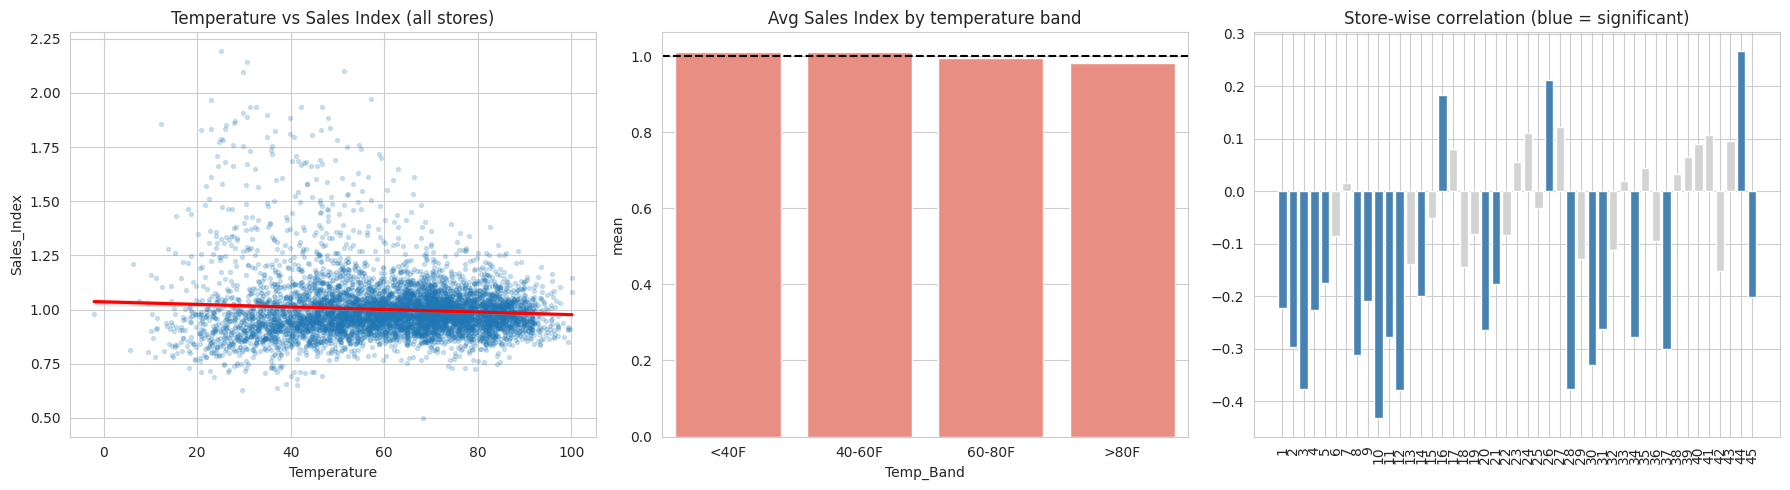

In [43]:
# Q1(c) TEMPERATURE vs SALES
r_t, p_t = stats.pearsonr(df["Temperature_dm"], df["Sales_Index"])
rho_t, prho_t = stats.spearmanr(df["Temperature_dm"], df["Sales_Index"])
print(f"OVERALL (store-adjusted): Pearson r={r_t:.3f} (p={p_t:.4g}) | Spearman rho={rho_t:.3f} (p={prho_t:.4g})")

# Temperature is strongly tied to season (cold = Nov/Dec festive weeks). Remove festive effect to see 'pure' effect.
calm = df[(df.Holiday_Flag == 0) & (~df.Month.isin([11, 12]))]
r_c, p_c = stats.pearsonr(calm["Temperature_dm"], calm["Sales_Index"])
print(f"Excluding holiday weeks & Nov/Dec : Pearson r={r_c:.3f} (p={p_c:.4g})")

df["Temp_Band"] = pd.cut(df["Temperature"], [-20, 40, 60, 80, 120], labels=["<40F", "40-60F", "60-80F", ">80F"])
band = df.groupby("Temp_Band", observed=True)["Sales_Index"].agg(["mean", "count"])
display(band)
kw_t, pk_t = stats.kruskal(*[g["Sales_Index"].values for _, g in df.groupby("Temp_Band", observed=True)])
print(f"Temperature bands differ? Kruskal H={kw_t:.1f}, p={pk_t:.4g}")

rows = []
for s, g in df.groupby("Store"):
    r, p = stats.pearsonr(g["Temperature"], g["Weekly_Sales"]); rows.append({"Store": s, "Correlation": r, "P_value": p})
tc = pd.DataFrame(rows).set_index("Store"); tc["Significant"] = tc.P_value < 0.05
print(f"Stores with significant temperature relation: {tc.Significant.sum()} of {len(tc)} "
      f"(negative: {((tc.Significant) & (tc.Correlation < 0)).sum()}, positive: {((tc.Significant) & (tc.Correlation > 0)).sum()})")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.regplot(data=df, x="Temperature", y="Sales_Index", ax=axes[0], scatter_kws={"alpha": .2, "s": 8}, line_kws={"color": "red"})
axes[0].set_title("Temperature vs Sales Index (all stores)")
sns.barplot(data=band.reset_index(), x="Temp_Band", y="mean", ax=axes[1], color="salmon"); axes[1].axhline(1, color="k", ls="--")
axes[1].set_title("Avg Sales Index by temperature band")
axes[2].bar(tc.index.astype(str), tc.Correlation, color=["steelblue" if s else "lightgrey" for s in tc.Significant])
axes[2].set_title("Store-wise correlation (blue = significant)"); axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()


OVERALL (store-adjusted): Pearson r=0.023 (p=0.07031) | Spearman rho=0.087 (p=2.298e-12)
Significant NEGATIVE stores: 8 | significant POSITIVE: 14 | not significant: 23

Most NEGATIVELY affected by rising CPI:


,Correlation,P_value,Pct_sales_change_per_1pt_CPI,Significant
Store,,,,
36,-0.915,0.000,-3.448,True
35,-0.424,0.000,-3.994,True
14,-0.420,0.000,-1.835,True
30,-0.298,0.000,-0.357,True
43,-0.286,0.001,-0.445,True


Most POSITIVELY related to rising CPI:


,Correlation,P_value,Pct_sales_change_per_1pt_CPI,Significant
Store,,,,
38,0.813,0.000,4.850,True
44,0.740,0.000,3.258,True
39,0.428,0.000,1.487,True
41,0.392,0.000,1.814,True
42,0.361,0.000,1.754,True


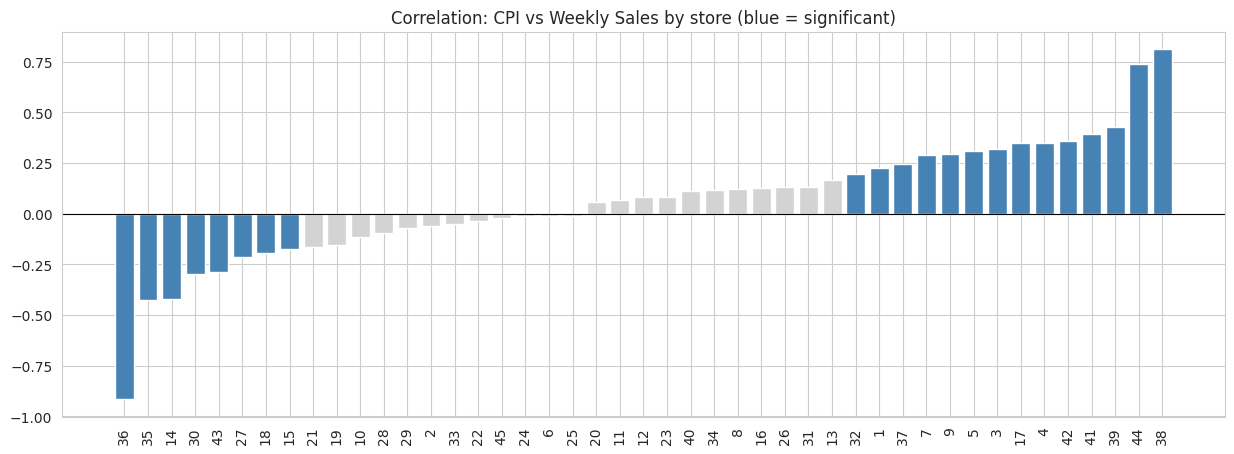

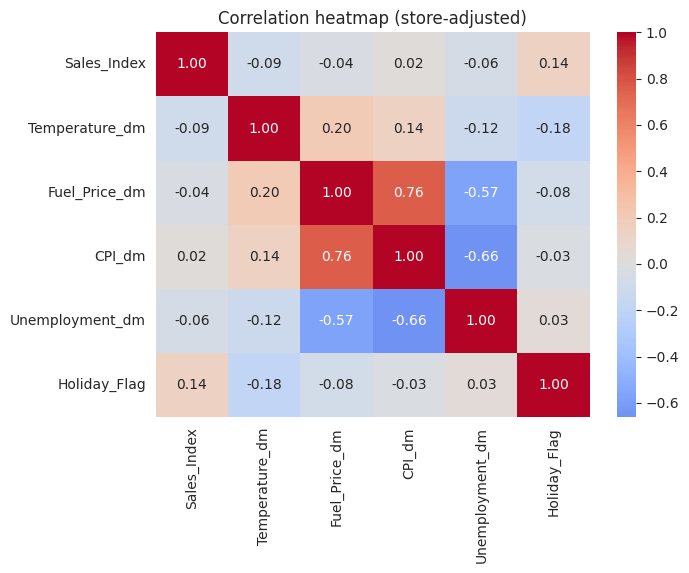

CAUTION: CPI rises steadily with time, so its effect is mixed with time trend. Correlation != causation.


In [44]:
# Q1(d) CPI vs SALES
r_cpi, p_cpi = stats.pearsonr(df["CPI_dm"], df["Sales_Index"])
rho_cpi, prho_cpi = stats.spearmanr(df["CPI_dm"], df["Sales_Index"])
print(f"OVERALL (store-adjusted): Pearson r={r_cpi:.3f} (p={p_cpi:.4g}) | Spearman rho={rho_cpi:.3f} (p={prho_cpi:.4g})")

rows = []
for s, g in df.groupby("Store"):
    r, p = stats.pearsonr(g["CPI"], g["Weekly_Sales"]); lr = stats.linregress(g["CPI"], g["Weekly_Sales"])
    rows.append({"Store": s, "Correlation": r, "P_value": p, "Pct_sales_change_per_1pt_CPI": lr.slope / g["Weekly_Sales"].mean() * 100})
cp = pd.DataFrame(rows).set_index("Store"); cp["Significant"] = cp.P_value < 0.05
print(f"Significant NEGATIVE stores: {((cp.Significant) & (cp.Correlation < 0)).sum()} | significant POSITIVE: {((cp.Significant) & (cp.Correlation > 0)).sum()} | not significant: {(~cp.Significant).sum()}")
print("\nMost NEGATIVELY affected by rising CPI:"); display(cp[cp.Significant].sort_values("Correlation").head(5))
print("Most POSITIVELY related to rising CPI:");  display(cp[cp.Significant].sort_values("Correlation", ascending=False).head(5))

cps = cp.sort_values("Correlation")
plt.figure(figsize=(15, 5))
plt.bar(cps.index.astype(str), cps.Correlation, color=["steelblue" if s else "lightgrey" for s in cps.Significant])
plt.axhline(0, color="black", lw=.8); plt.xticks(rotation=90)
plt.title("Correlation: CPI vs Weekly Sales by store (blue = significant)"); plt.show()

# Overall driver heatmap (store-adjusted)
hm = df[["Sales_Index", "Temperature_dm", "Fuel_Price_dm", "CPI_dm", "Unemployment_dm", "Holiday_Flag"]].corr()
plt.figure(figsize=(7, 5)); sns.heatmap(hm, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (store-adjusted)"); plt.show()
print("CAUTION: CPI rises steadily with time, so its effect is mixed with time trend. Correlation != causation.")


In [45]:
# CONTROLLED MODEL (checks a, c, d together)
fe = smf.ols("np.log(Weekly_Sales) ~ Unemployment + Temperature + Fuel_Price + CPI + Holiday_Flag + C(Store)", data=df).fit()
vars_ = ["Unemployment", "Temperature", "Fuel_Price", "CPI", "Holiday_Flag"]
ctrl = pd.DataFrame({"Coef": fe.params[vars_], "P_value": fe.pvalues[vars_]})
ctrl["Pct_effect_per_unit"] = (np.exp(ctrl["Coef"]) - 1) * 100
ctrl["Significant"] = ctrl["P_value"] < 0.05
print(f"Store-fixed-effects regression, R-squared = {fe.rsquared:.3f}")
display(ctrl)


Store-fixed-effects regression, R-squared = 0.958


,Coef,P_value,Pct_effect_per_unit,Significant
Unemployment,-0.019,0.000,-1.916,True
Temperature,-0.000,0.002,-0.030,True
Fuel_Price,-0.028,0.000,-2.754,True
CPI,0.002,0.011,0.198,True
Holiday_Flag,0.057,0.000,5.824,True


TOP 10 STORES (historical total sales):


,Total_Sales,Avg_Weekly_Sales,Std,Max_Week,CV_%,Share_of_chain_%,Growth_2012_vs_2011_%,Rank
Store,,,,,,,,
20,"301,397,792.460","2,107,676.870","275,900.563","3,766,687.430",13.090,4.474,3.221,1
4,"299,543,953.380","2,094,712.961","266,201.442","3,676,388.980",12.708,4.446,5.028,2
14,"288,999,911.340","2,020,978.401","317,569.949","3,818,686.450",15.714,4.290,-9.351,3
13,"286,517,703.800","2,003,620.306","265,506.996","3,595,903.200",13.251,4.253,4.775,4
2,"275,382,440.980","1,925,751.336","237,683.695","3,436,007.680",12.342,4.087,4.330,5
10,"271,617,713.890","1,899,424.573","302,262.063","3,749,057.690",15.913,4.032,0.986,6
27,"253,855,916.880","1,775,216.202","239,930.136","3,078,162.080",13.516,3.768,-2.551,7
6,"223,756,130.640","1,564,728.186","212,525.856","2,727,575.180",13.582,3.321,3.946,8
1,"222,402,808.850","1,555,264.398","155,980.768","2,387,950.200",10.029,3.301,4.928,9


Top 5 stores contribute 21.5% of chain sales; top 10 contribute 39.1%
Fastest growing stores (2012 vs 2011, Feb-Oct):


,Avg_Weekly_Sales,Growth_2012_vs_2011_%
Store,,
38,"385,731.653",13.861
44,"302,748.866",11.553
39,"1,450,668.129",10.481
3,"402,704.441",9.523
5,"318,011.810",8.574


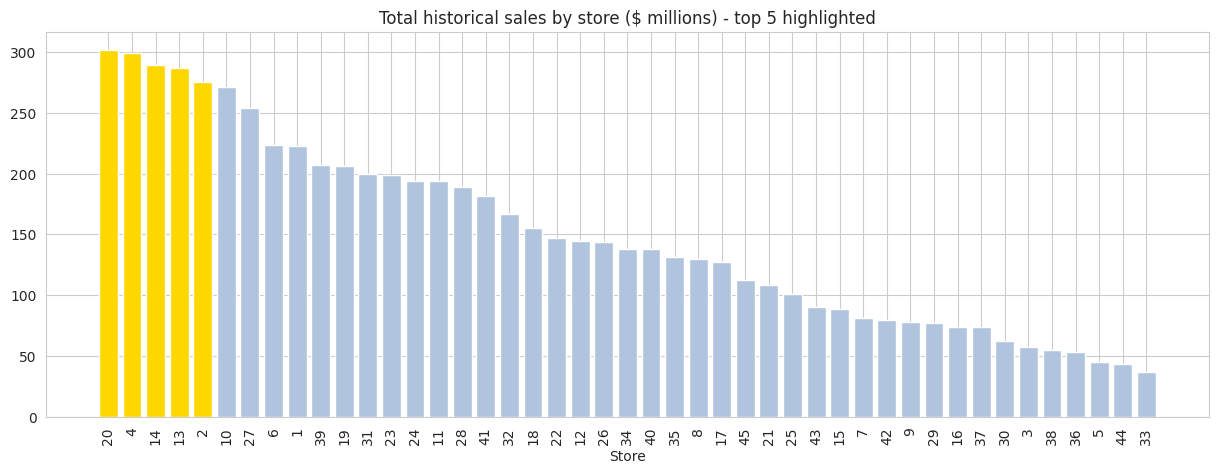

In [46]:
# Q1(e) TOP PERFORMING STORES
sp = df.groupby("Store").agg(Total_Sales=("Weekly_Sales", "sum"), Avg_Weekly_Sales=("Weekly_Sales", "mean"),
                              Std=("Weekly_Sales", "std"), Max_Week=("Weekly_Sales", "max"))
sp["CV_%"] = sp["Std"] / sp["Avg_Weekly_Sales"] * 100          # lower = more stable demand
sp["Share_of_chain_%"] = sp["Total_Sales"] / sp["Total_Sales"].sum() * 100
g = df[df.Month.between(2, 10)].groupby(["Store", "Year"])["Weekly_Sales"].mean().unstack()   # same Feb-Oct window each year
sp["Growth_2012_vs_2011_%"] = (g[2012] / g[2011] - 1) * 100
sp["Rank"] = sp["Total_Sales"].rank(ascending=False).astype(int)
sp = sp.sort_values("Rank")
print("TOP 10 STORES (historical total sales):"); display(sp.head(10))
print(f"Top 5 stores contribute {sp.head(5)['Share_of_chain_%'].sum():.1f}% of chain sales; top 10 contribute {sp.head(10)['Share_of_chain_%'].sum():.1f}%")
print("Fastest growing stores (2012 vs 2011, Feb-Oct):"); display(sp.sort_values("Growth_2012_vs_2011_%", ascending=False).head(5)[["Avg_Weekly_Sales", "Growth_2012_vs_2011_%"]])

plt.figure(figsize=(15, 5))
plt.bar(sp.index.astype(str), sp["Total_Sales"] / 1e6, color=["gold" if r <= 5 else "lightsteelblue" for r in sp.Rank])
plt.title("Total historical sales by store ($ millions) - top 5 highlighted"); plt.xlabel("Store"); plt.xticks(rotation=90); plt.show()


Best store (by avg weekly sales): 20 | Worst store: 33
Avg weekly sales  -> Store 20: $2,107,677 | Store 33: $259,862
Absolute gap: $1,847,815 per week | Best is 8.1x the worst

Welch t-test: t=79.8, p=3.52e-121 | Paired t-test: p=3.83e-120 | Mann-Whitney: p=2.11e-48
Cohen's d = 9.4 (huge effect) | 95% CI of weekly gap: $1,802,038 to $1,893,592
=> Gap is STATISTICALLY SIGNIFICANT
All 45 stores - ANOVA F=1613.3, p=0 | Kruskal H=6144.3, p=0  -> stores differ significantly


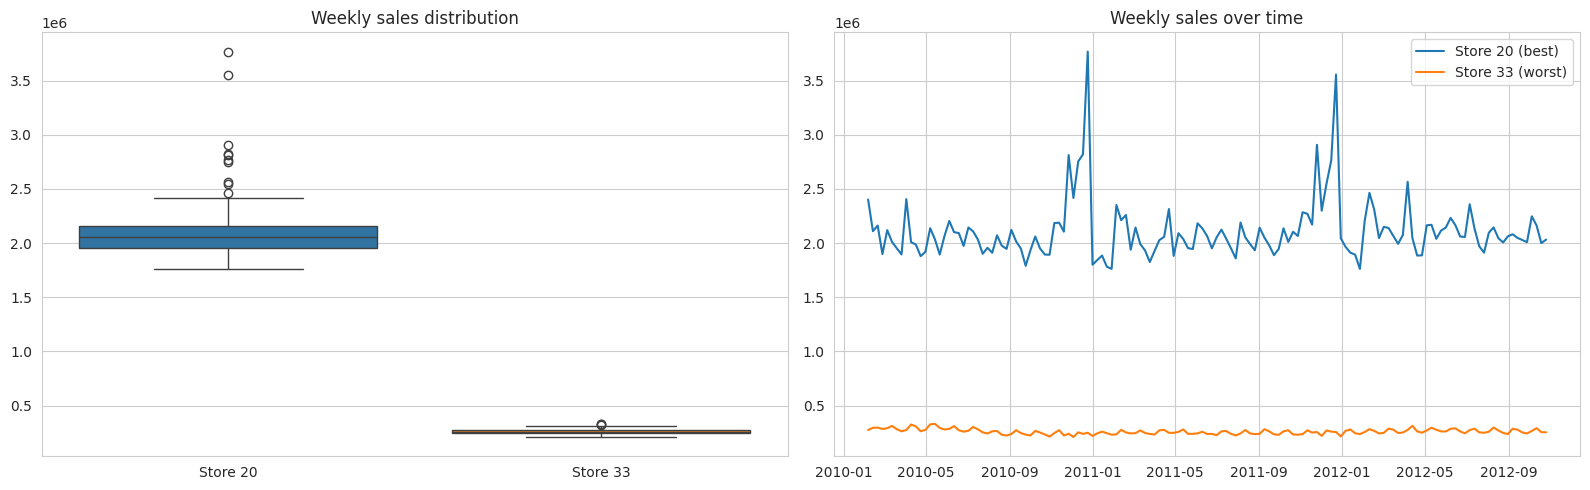

In [47]:
#  Q1(f) WORST STORE & SIGNIFICANCE OF GAP
best, worst = sp["Avg_Weekly_Sales"].idxmax(), sp["Avg_Weekly_Sales"].idxmin()
a, b = sales_wide[best], sales_wide[worst]
print(f"Best store (by avg weekly sales): {best} | Worst store: {worst}")
print(f"Avg weekly sales  -> Store {best}: ${a.mean():,.0f} | Store {worst}: ${b.mean():,.0f}")
print(f"Absolute gap: ${a.mean() - b.mean():,.0f} per week | Best is {a.mean() / b.mean():.1f}x the worst")

t, p = stats.ttest_ind(a, b, equal_var=False)
tp, pp = stats.ttest_rel(a, b)
u, pu = stats.mannwhitneyu(a, b, alternative="two-sided")
sd_p = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2); d = (a.mean() - b.mean()) / sd_p
se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
dfw = se ** 4 / ((a.var(ddof=1) / len(a)) ** 2 / (len(a) - 1) + (b.var(ddof=1) / len(b)) ** 2 / (len(b) - 1))
ci = ((a.mean() - b.mean()) - stats.t.ppf(.975, dfw) * se, (a.mean() - b.mean()) + stats.t.ppf(.975, dfw) * se)
print(f"\nWelch t-test: t={t:.1f}, p={p:.3g} | Paired t-test: p={pp:.3g} | Mann-Whitney: p={pu:.3g}")
print(f"Cohen's d = {d:.1f} (huge effect) | 95% CI of weekly gap: ${ci[0]:,.0f} to ${ci[1]:,.0f}")
print("=> Gap is STATISTICALLY SIGNIFICANT" if p < 0.05 else "=> Gap NOT significant")
gap_ratio, p_gap = a.mean() / b.mean(), p      # saved for the final summary (a, p get reused later)

F, pF = stats.f_oneway(*[sales_wide[c] for c in sales_wide.columns])
H, pH = stats.kruskal(*[sales_wide[c] for c in sales_wide.columns])
print(f"All 45 stores - ANOVA F={F:.1f}, p={pF:.3g} | Kruskal H={H:.1f}, p={pH:.3g}  -> stores differ significantly")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=pd.DataFrame({f"Store {best}": a, f"Store {worst}": b}), ax=axes[0]); axes[0].set_title("Weekly sales distribution")
axes[1].plot(a.index, a.values, label=f"Store {best} (best)"); axes[1].plot(b.index, b.values, label=f"Store {worst} (worst)")
axes[1].legend(); axes[1].set_title("Weekly sales over time"); plt.tight_layout(); plt.show()


In [48]:
#  Q2 FORECASTING: SETUP
HORIZON = 12
assert (sales_wide.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all(), "Weeks are not evenly spaced"
macro = {c: df.pivot(index="Date", columns="Store", values=c).sort_index() for c in ["CPI", "Unemployment", "Fuel_Price"]}

# Known holiday weeks: history comes from data; Thanksgiving/Christmas weeks of 2012 and Super Bowl 2013 added for the future
holiday_list = list(pd.to_datetime(df.loc[df.Holiday_Flag == 1, "Date"].unique())) + \
    [pd.Timestamp("2012-11-23"), pd.Timestamp("2012-12-28"), pd.Timestamp("2013-02-08")]

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def mape(y, p): y, p = np.asarray(y, float), np.asarray(p, float); return float(np.mean(np.abs((y - p) / y)) * 100)
def future_index(train_wide):
    return pd.date_range(train_wide.index[-1] + pd.Timedelta(days=7), periods=HORIZON, freq="7D")

print("Last date in data:", sales_wide.index[-1].date(), "| Forecast window:",
      future_index(sales_wide)[0].date(), "to", future_index(sales_wide)[-1].date())


Last date in data: 2012-10-26 | Forecast window: 2012-11-02 to 2013-01-18


In [49]:
#  FORECASTING MODELS
# 1) Seasonal naive baseline: "same week last year"
def fc_naive(train_wide):
    out = {s: train_wide[s].values[-52:-52 + HORIZON] for s in train_wide.columns}
    return pd.DataFrame(out, index=future_index(train_wide))

# 2) Holt-Winters (trend + 52-week seasonality)
def fc_hw(train_wide):
    out = {}
    for s in train_wide.columns:
        y = train_wide[s].values
        try:
            m = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add",
                                     seasonal_periods=52, initialization_method="heuristic").fit()
            f = np.asarray(m.forecast(HORIZON))
            if not np.all(np.isfinite(f)): raise ValueError
        except Exception:
            f = y[-52:-52 + HORIZON]
        out[s] = f
    return pd.DataFrame(out, index=future_index(train_wide))

# 3) SARIMA(1,0,0)(0,1,0,52)
def fc_sarima(train_wide):
    out = {}
    for s in train_wide.columns:
        y = train_wide[s].values
        try:
            m = SARIMAX(y, order=(1, 0, 0), seasonal_order=(0, 1, 0, 52),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            f = np.asarray(m.forecast(HORIZON))
            if not np.all(np.isfinite(f)): raise ValueError
        except Exception:
            f = y[-52:-52 + HORIZON]
        out[s] = f
    return pd.DataFrame(out, index=future_index(train_wide))

# 4) & 5) Global machine-learning models with lag features
#    Every lag is >= 12 weeks, so ONE model can forecast all 12 weeks directly (no recursive error build-up).
LAGS = [12, 13, 14, 26, 51, 52, 53]

def build_panel(sales_ext, macro_ext):
    ls = np.log(sales_ext)
    wk = sales_ext.index.isocalendar().week.astype(int).values
    frames = []
    for s in sales_ext.columns:
        f = pd.DataFrame(index=sales_ext.index)
        f["Store"] = s
        f["y"] = ls[s]
        for L in LAGS:
            f[f"lag_{L}"] = ls[s].shift(L)
        f["roll4"] = ls[s].shift(12).rolling(4).mean()
        f["roll8"] = ls[s].shift(12).rolling(8).mean()
        for c in macro_ext:
            f[f"{c}_l12"] = macro_ext[c][s].shift(12)
        f["week"] = wk
        f["month"] = sales_ext.index.month
        f["holiday"] = sales_ext.index.isin(holiday_list).astype(int)
        frames.append(f)
    out = pd.concat(frames)
    out.index.name = "Date"
    return out.reset_index()

try:
    from xgboost import XGBRegressor
    def make_xgb():
        return XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8,
                            colsample_bytree=0.8, random_state=42, n_jobs=-1)
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    def make_xgb():
        return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_depth=4, random_state=42)
    print("xgboost not found -> using sklearn HistGradientBoosting instead")


In [ ]:

def fc_ml(train_wide, kind):
    fut = future_index(train_wide)
    ext = train_wide.reindex(train_wide.index.append(fut)); ext.index.name = "Date"
    mac = {c: macro[c].loc[:train_wide.index[-1]].reindex(ext.index) for c in macro}
    panel = build_panel(ext, mac)
    panel["store_level"] = panel["Store"].map(np.log(train_wide).mean())
    feats = [c for c in panel.columns if c not in ("Date", "Store", "y")]
    train = panel[panel.Date <= train_wide.index[-1]].dropna(subset=feats + ["y"])
    test = panel[panel.Date > train_wide.index[-1]]
    assert test[feats].notna().all().all(), "future features contain NaN"
    model = (RandomForestRegressor(n_estimators=400, min_samples_leaf=2, max_features=0.7, n_jobs=-1, random_state=42)
             if kind == "rf" else make_xgb())
    model.fit(train[feats], train["y"])
    test = test.assign(pred=np.exp(model.predict(test[feats])))
    return test.pivot(index="Date", columns="Store", values="pred")

MODELS = {"Seasonal Naive": fc_naive, "Holt-Winters": fc_hw, "SARIMA": fc_sarima,
          "Random Forest": lambda t: fc_ml(t, "rf"), "XGBoost": lambda t: fc_ml(t, "xgb")}

done: Seasonal Naive
done: Holt-Winters
done: SARIMA
done: Random Forest
done: XGBoost

MODEL COMPARISON (last 12 weeks hold-out):


,RMSE (all store-weeks),Avg store MAPE %,Median store MAPE %,Chain-total MAPE %
Model,,,,
Random Forest,"60,562.722",3.956,3.446,1.244
Holt-Winters,"68,420.572",4.057,3.251,2.383
XGBoost,"64,050.187",4.263,3.683,1.698
SARIMA,"81,497.416",4.794,4.096,2.105
Seasonal Naive,"85,365.674",5.458,4.149,2.117



BEST MODEL: Random Forest


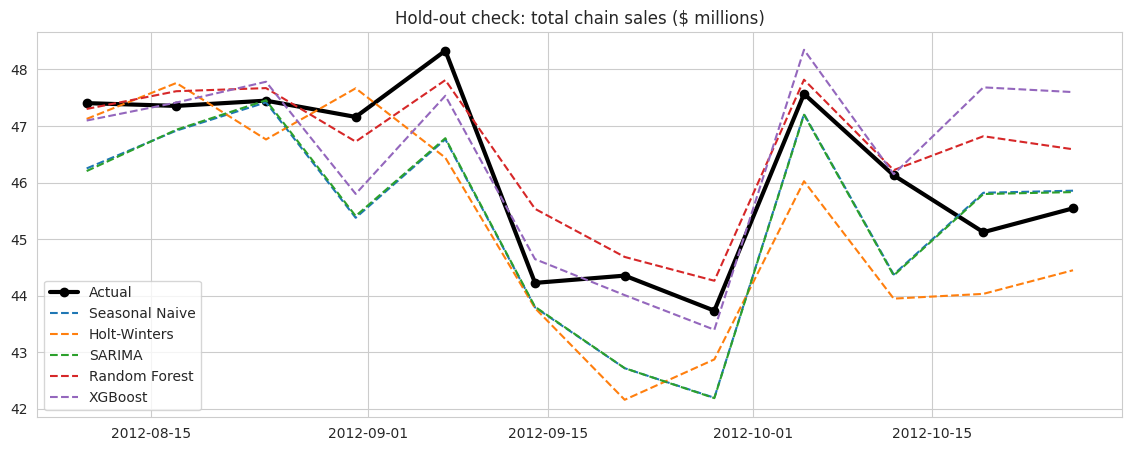

NOTE: this hold-out window (Aug-Oct 2012) has no major holiday, so festive-week accuracy should be monitored separately.


In [50]:
# MODEL EVALUATION (hold out the last 12 weeks, train on the rest)
train_h, test_h = sales_wide.iloc[:-HORIZON], sales_wide.iloc[-HORIZON:]
preds, rows = {}, []
for name, fn in MODELS.items():
    p = fn(train_h)
    assert (p.index == test_h.index).all() and list(p.columns) == list(test_h.columns)
    preds[name] = p
    ape = np.abs(test_h - p) / test_h * 100
    rows.append({"Model": name, "RMSE (all store-weeks)": rmse(test_h.values, p.values),
                 "Avg store MAPE %": ape.mean().mean(), "Median store MAPE %": ape.mean().median(),
                 "Chain-total MAPE %": mape(test_h.sum(axis=1), p.sum(axis=1))})
    print(f"done: {name}")
results = pd.DataFrame(rows).set_index("Model").sort_values("Avg store MAPE %")
print("\nMODEL COMPARISON (last 12 weeks hold-out):"); display(results)
best_model = results.index[0]
print(f"\nBEST MODEL: {best_model}")

plt.figure(figsize=(14, 5))
plt.plot(test_h.index, test_h.sum(axis=1) / 1e6, "k-o", lw=3, label="Actual")
for n, p in preds.items():
    plt.plot(p.index, p.sum(axis=1) / 1e6, "--", label=n)
plt.title("Hold-out check: total chain sales ($ millions)"); plt.legend(); plt.show()

ape_best = np.abs(test_h - preds[best_model]) / test_h * 100
print("NOTE: this hold-out window (Aug-Oct 2012) has no major holiday, so festive-week accuracy should be monitored separately.")


Saved: walmart_12week_forecast.csv


,Date,Store,Forecast_Sales,Safety_Buffer_%,Forecast_With_Buffer
0,2012-11-02,1,"1,706,909.065",3.249,"1,762,360.712"
1,2012-11-09,1,"1,638,314.249",3.249,"1,691,537.485"
2,2012-11-16,1,"1,613,897.458",3.249,"1,666,327.476"
3,2012-11-23,1,"2,004,113.967",3.249,"2,069,220.787"
4,2012-11-30,1,"1,650,808.756",3.249,"1,704,437.896"
5,2012-12-07,1,"1,802,103.459",3.249,"1,860,647.648"
6,2012-12-14,1,"1,882,370.772",3.249,"1,943,522.571"
7,2012-12-21,1,"2,183,370.448",3.249,"2,254,300.699"
8,2012-12-28,1,"1,584,068.542",3.249,"1,635,529.520"
9,2013-01-04,1,"1,604,122.540",3.249,"1,656,235.004"



Chain forecast (next 12 weeks): $626.2M vs last year's same weeks $627.3M (-0.2%)
Peak forecast week: 2012-12-21 -> $73.1M


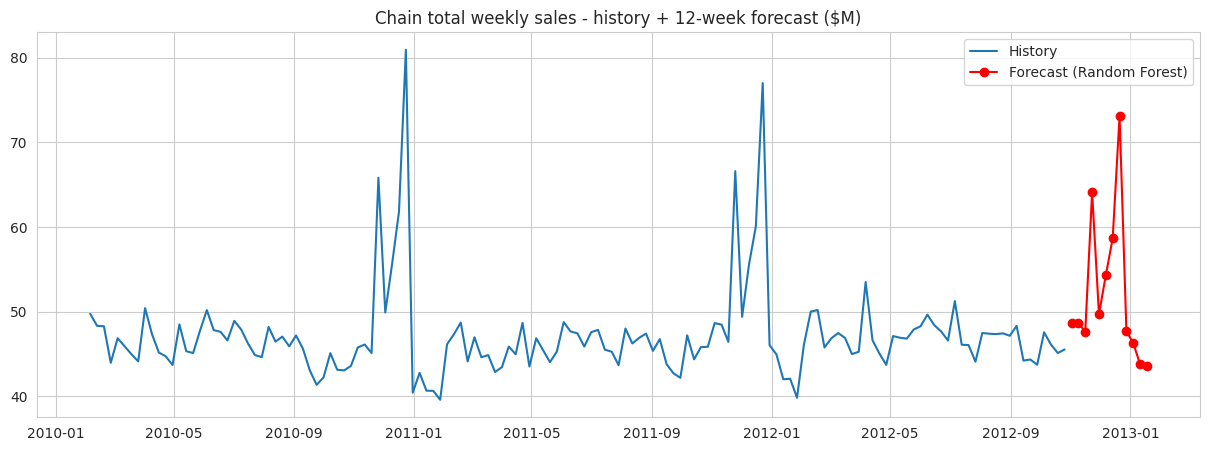

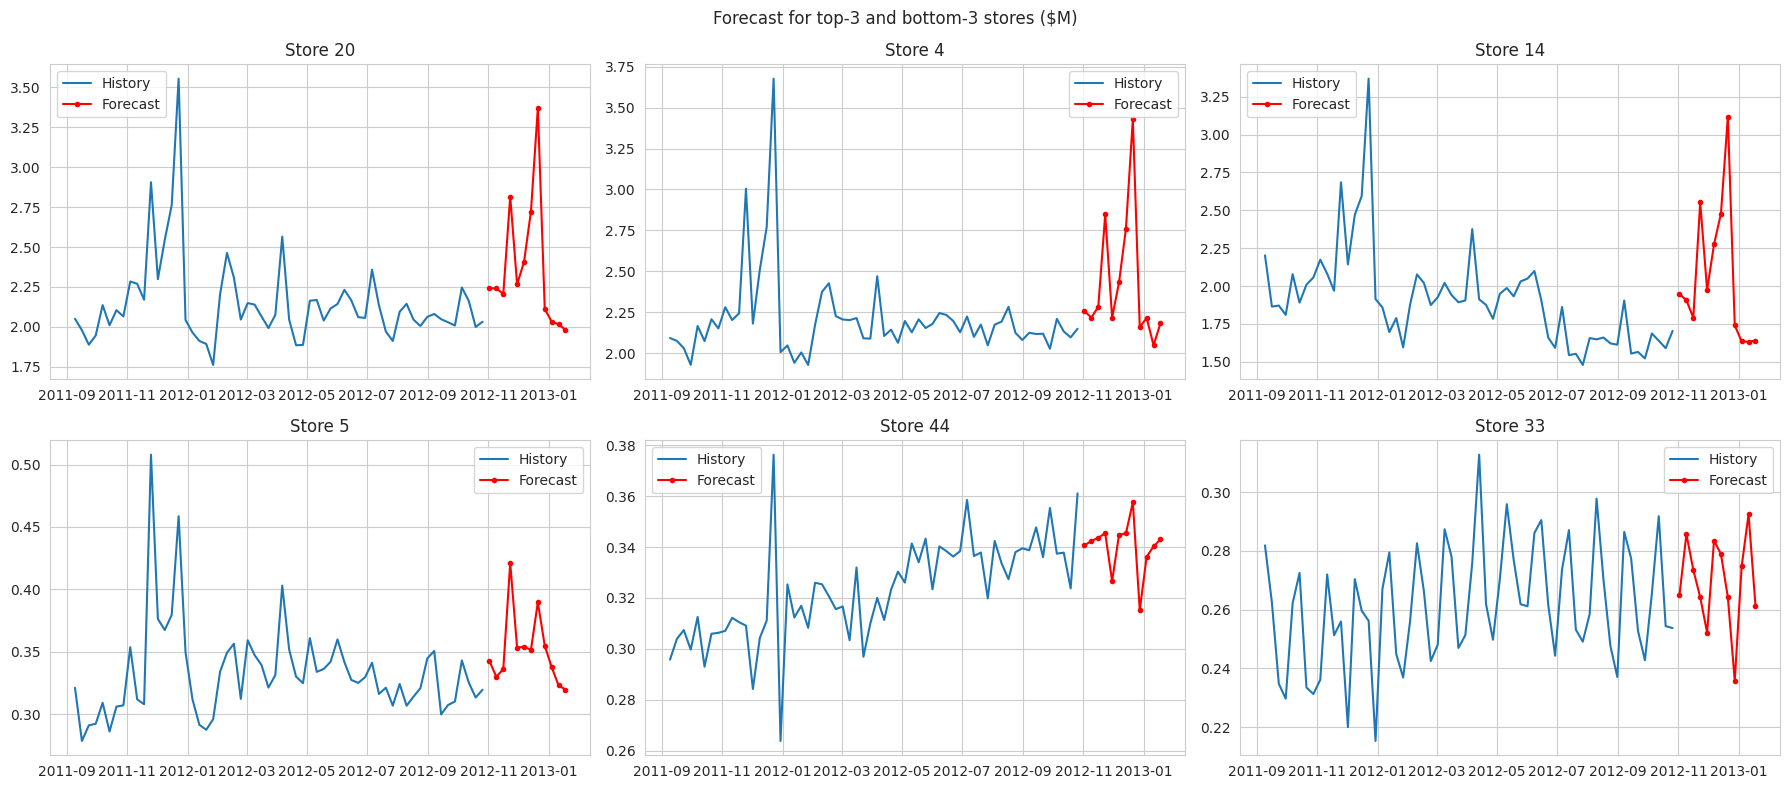

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
# FINAL 12-WEEK FORECAST FOR EVERY STORE
final_fc = MODELS[best_model](sales_wide)
buffer_pct = ape_best.quantile(0.90)      # 90th-percentile error per store = safety-stock buffer
fut = final_fc.index

long_fc = final_fc.stack().rename("Forecast_Sales").reset_index()
long_fc.columns = ["Date", "Store", "Forecast_Sales"]
long_fc["Safety_Buffer_%"] = long_fc["Store"].map(buffer_pct)
long_fc["Forecast_With_Buffer"] = long_fc["Forecast_Sales"] * (1 + long_fc["Safety_Buffer_%"] / 100)
long_fc = long_fc.sort_values(["Store", "Date"]).reset_index(drop=True)
long_fc.to_csv("walmart_12week_forecast.csv", index=False)
print("Saved: walmart_12week_forecast.csv"); display(long_fc.head(15))

# Year-on-year view for the same 12 weeks
ly = sales_wide.loc[fut - pd.Timedelta(weeks=52)]
yoy = pd.DataFrame({"Store": final_fc.columns, "Forecast_12wk": final_fc.sum().values, "LastYear_12wk": ly.sum().values})
yoy["YoY_%"] = (yoy["Forecast_12wk"] / yoy["LastYear_12wk"] - 1) * 100
print(f"\nChain forecast (next 12 weeks): ${final_fc.sum().sum() / 1e6:,.1f}M vs last year's same weeks ${ly.sum().sum() / 1e6:,.1f}M "
      f"({(final_fc.sum().sum() / ly.sum().sum() - 1) * 100:+.1f}%)")
peak = final_fc.sum(axis=1).idxmax()
print(f"Peak forecast week: {peak.date()} -> ${final_fc.sum(axis=1).max() / 1e6:,.1f}M")

hist_total = sales_wide.sum(axis=1) / 1e6
plt.figure(figsize=(15, 5))
plt.plot(hist_total.index, hist_total.values, label="History")
plt.plot(fut, final_fc.sum(axis=1) / 1e6, "r-o", label=f"Forecast ({best_model})")
plt.title("Chain total weekly sales - history + 12-week forecast ($M)"); plt.legend(); plt.show()

show = list(sp.index[:3]) + list(sp.index[-3:])
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, s in zip(axes.ravel(), show):
    a.plot(sales_wide.index[-60:], sales_wide[s].iloc[-60:] / 1e6, label="History")
    a.plot(fut, final_fc[s] / 1e6, "r-o", ms=3, label="Forecast")
    a.set_title(f"Store {s}"); a.legend()
plt.suptitle("Forecast for top-3 and bottom-3 stores ($M)"); plt.tight_layout(); plt.show()

try:
    from google.colab import files
    files.download("walmart_12week_forecast.csv")
except Exception:
    pass



In [56]:
# BUSINESS INSIGHTS SUMMARY

print("KEY FINDINGS & RECOMMENDATIONS")
print("=" * 35)
print(f"1. Unemployment : store-adjusted r={r_all:.3f}; {len(neg)} stores show a significant negative link "
      f"(most affected: {list(neg.index[:3])}).")
print(f"2. Seasonality  : confirmed (Kruskal p={pk:.2g}); peak months {list(month_idx.sort_values(ascending=False).head(2).index)}; "
      f"pre-Christmas weeks run {(px / base - 1) * 100:.0f}% above normal.")
flip = "sign changes once festive weeks are removed -> temperature mostly acts as a proxy for season" if np.sign(r_t) != np.sign(r_c) else "same direction even without festive weeks"
print(f"3. Temperature  : store-adjusted r={r_t:.3f}; excluding holiday/Nov-Dec weeks r={r_c:.3f} ({flip}).")
print(f"4. CPI          : store-adjusted r={r_cpi:.3f}; effect differs by store (see bar chart).")
print(f"5. Top stores   : {list(sp.index[:5])} generate {sp.head(5)['Share_of_chain_%'].sum():.0f}% of chain sales.")
print(f"6. Worst store  : Store {worst}; best store {best} sells {gap_ratio:.1f}x more per week (p={p_gap:.2g}).")
print(f"7. Forecast     : best model = {best_model}, avg store MAPE = {results.iloc[0]['Avg store MAPE %']:.1f}% on hold-out.")
print("\nRECOMMENDATIONS")
print(" - Stock up ahead of Thanksgiving and the 2 weeks before Christmas; use Forecast_With_Buffer as the order quantity.")
print(" - Use the 90th-percentile error buffer per store: volatile stores get more safety stock, stable stores less.")
print(" - Review underperforming stores (low sales, high volatility) for local promotions / assortment changes.")
print(" - Re-train the model every week with new data and track MAPE to catch drift early.")


KEY FINDINGS & RECOMMENDATIONS
1. Unemployment : store-adjusted r=-0.055; 14 stores show a significant negative link (most affected: [38, 44, 39]).
2. Seasonality  : confirmed (Kruskal p=4.6e-216); peak months [12, 11]; pre-Christmas weeks run 44% above normal.
3. Temperature  : store-adjusted r=-0.093; excluding holiday/Nov-Dec weeks r=0.187 (sign changes once festive weeks are removed -> temperature mostly acts as a proxy for season).
4. CPI          : store-adjusted r=0.023; effect differs by store (see bar chart).
5. Top stores   : [20, 4, 14, 13, 2] generate 22% of chain sales.
6. Worst store  : Store 33; best store 20 sells 8.1x more per week (p=3.5e-121).
7. Forecast     : best model = Random Forest, avg store MAPE = 4.0% on hold-out.

RECOMMENDATIONS
 - Stock up ahead of Thanksgiving and the 2 weeks before Christmas; use Forecast_With_Buffer as the order quantity.
 - Use the 90th-percentile error buffer per store: volatile stores get more safety stock, stable stores less.
 - Re